<a href="https://colab.research.google.com/github/sada1908/edyoda_assign/blob/main/edyoda_MLmodelsComp_Assign01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [25]:
import pandas as pd
import numpy as np
from scipy.stats import boxcox
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import accuracy_score

In [26]:
df1_raw = pd.read_csv("/content/train.csv")
df2_raw = pd.read_csv("/content/test.csv")

In [27]:
df1 = df1_raw.copy()
df2 = df2_raw.copy()

In [28]:
df1.head()

,id,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,0,L50096,L,300.6,309.6,1596,36.1,140,0,0,0,0,0,0
1,1,M20343,M,302.6,312.1,1759,29.1,200,0,0,0,0,0,0
2,2,L49454,L,299.3,308.5,1805,26.5,25,0,0,0,0,0,0
3,3,L53355,L,301.0,310.9,1524,44.3,197,0,0,0,0,0,0
4,4,M24050,M,298.0,309.0,1641,35.4,34,0,0,0,0,0,0


In [8]:
df1.columns

Index(['id', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')

In [29]:
df1.shape,df2.shape

((136429, 14), (90954, 13))

In [30]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 136429 entries, 0 to 136428
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       136429 non-null  int64  
 1   Product ID               136429 non-null  object 
 2   Type                     136429 non-null  object 
 3   Air temperature [K]      136429 non-null  float64
 4   Process temperature [K]  136429 non-null  float64
 5   Rotational speed [rpm]   136429 non-null  int64  
 6   Torque [Nm]              136429 non-null  float64
 7   Tool wear [min]          136429 non-null  int64  
 8   Machine failure          136429 non-null  int64  
 9   TWF                      136429 non-null  int64  
 10  HDF                      136429 non-null  int64  
 11  PWF                      136429 non-null  int64  
 12  OSF                      136429 non-null  int64  
 13  RNF                      136429 non-null  int64  
dtypes: f

In [31]:
df1.describe()

,id,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000
mean,68214.000000,299.862776,309.941070,1520.331110,40.348643,104.408901,0.015744,0.001554,0.005160,0.002397,0.003958,0.002258
std,39383.804275,1.862247,1.385173,138.736632,8.502229,63.965040,0.124486,0.039389,0.071649,0.048899,0.062789,0.047461
min,0.000000,295.300000,305.800000,1181.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,34107.000000,298.300000,308.700000,1432.000000,34.600000,48.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,68214.000000,300.000000,310.000000,1493.000000,40.400000,106.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,102321.000000,301.200000,310.900000,1580.000000,46.100000,159.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,136428.000000,304.400000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [34]:
# Robust Scaling for Air and Process Temperature
scaler = RobustScaler()
df1[['Air temperature [K]', 'Process temperature [K]']] = scaler.fit_transform(df1[['Air temperature [K]', 'Process temperature [K]']])
df2[['Air temperature [K]', 'Process temperature [K]']] = scaler.transform(df2[['Air temperature [K]', 'Process temperature [K]']])

In [35]:
# Logarithmic transformation for Rotational speed (add 1 to avoid log(0))
df1['Rotational speed [rpm]'] = np.log1p(df1['Rotational speed [rpm]'])
df2['Rotational speed [rpm]'] = np.log1p(df2['Rotational speed [rpm]'])

In [36]:
# Box-Cox transformation for Tool wear (add 1 to avoid issues with zero values and apply only to positive values)
# Find the optimal lambda for the Box-Cox transformation
transformed_data, best_lambda = boxcox(df1['Tool wear [min]'] + 1)

# Apply the transformation with the found lambda
df1['Tool wear [min]'] = transformed_data
df2['Tool wear [min'] = boxcox(df2['Tool wear [min]'] + 1, lmbda=best_lambda)

In [37]:
display(df1.head())
display(df2.head())

,id,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,0,L50096,L,0.206897,-0.181818,7.375882,36.1,42.261651,0,0,0,0,0,0
1,1,M20343,M,0.896552,0.954545,7.473069,29.1,54.332488,0,0,0,0,0,0
2,2,L49454,L,-0.241379,-0.681818,7.498870,26.5,12.213368,0,0,0,0,0,0
3,3,L53355,L,0.344828,0.409091,7.329750,44.3,53.758531,0,0,0,0,0,0
4,4,M24050,M,-0.689655,-0.454545,7.403670,35.4,15.313390,0,0,0,0,0,0


,id,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],TWF,HDF,PWF,OSF,RNF,Tool wear [min
0,136429,L50896,L,0.793103,0.681818,7.313220,38.0,60,0,0,0,0,0,23.114860
1,136430,L53866,L,0.586207,0.454545,7.446585,28.8,17,0,0,0,0,0,9.159429
2,136431,L50498,L,0.448276,0.181818,7.330405,37.7,96,0,0,0,0,0,32.346224
3,136432,M21232,M,0.034483,-0.181818,7.299797,47.6,5,0,0,0,0,0,3.531733
4,136433,M19751,M,1.172414,1.045455,7.323831,41.3,114,0,0,0,0,0,36.543902


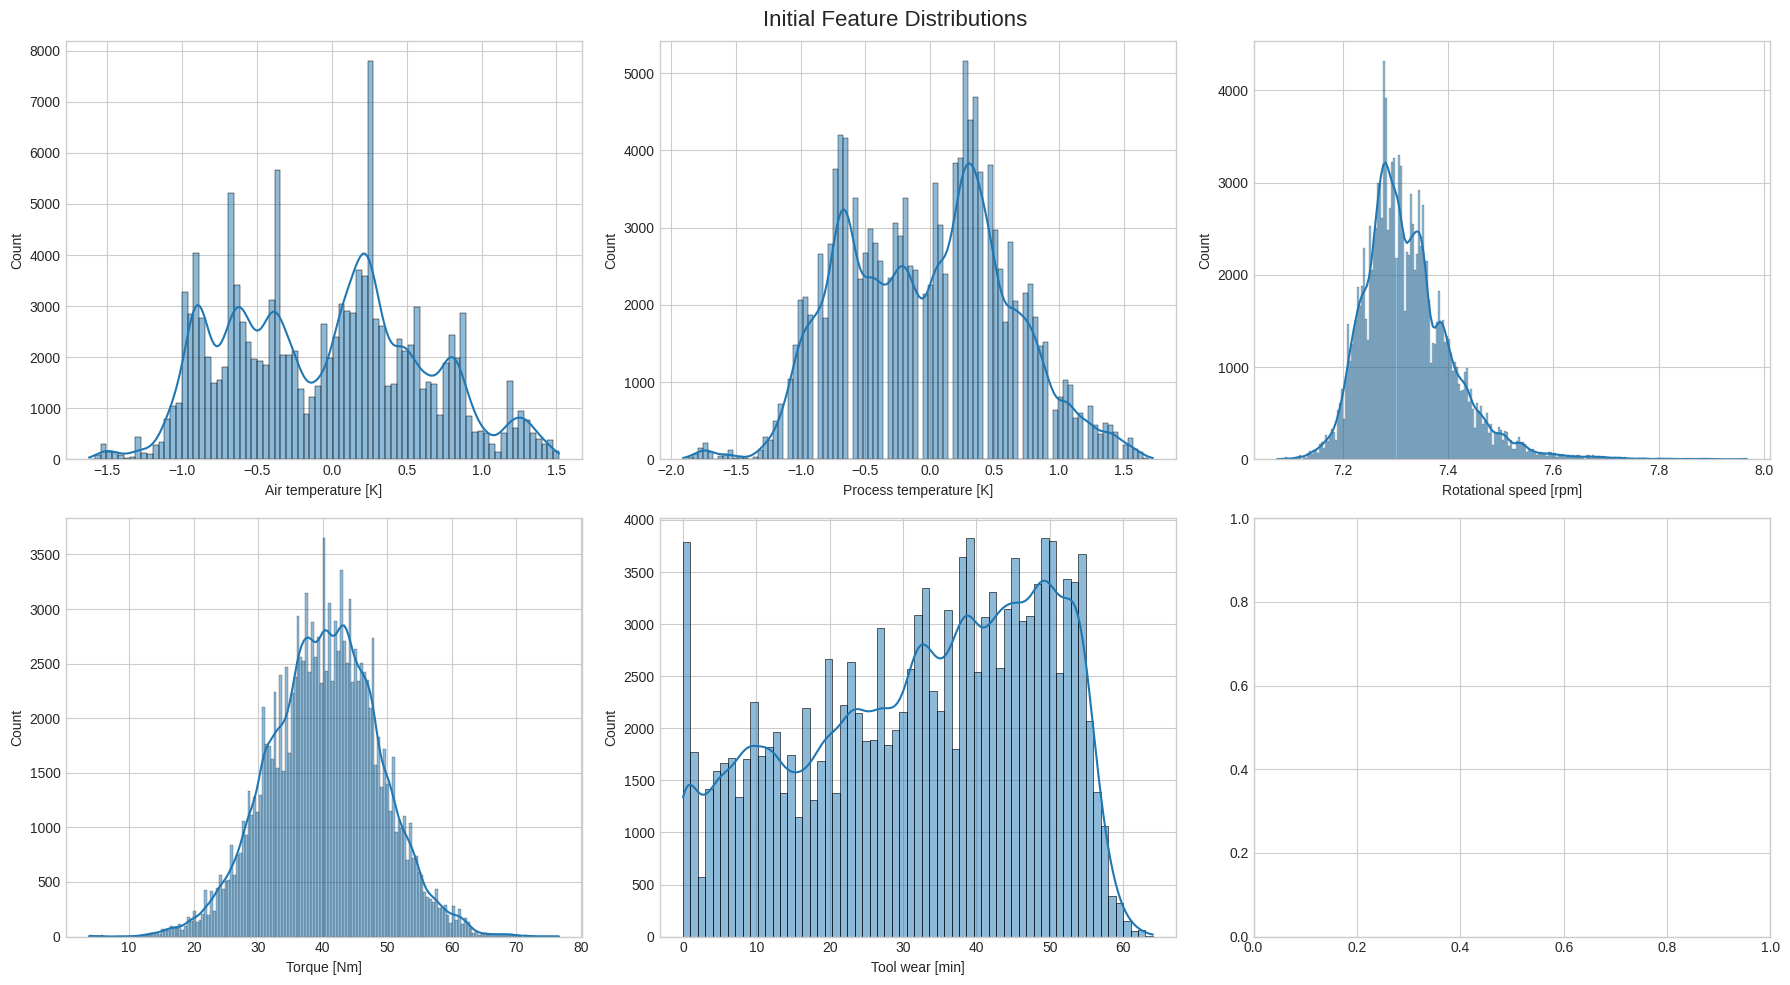

In [38]:
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Initial Feature Distributions', fontsize=16)

sns.histplot(df1['Air temperature [K]'], ax=axes[0, 0], kde=True)
sns.histplot(df1['Process temperature [K]'], ax=axes[0, 1], kde=True)
sns.histplot(df1['Rotational speed [rpm]'], ax=axes[0, 2], kde=True)
sns.histplot(df1['Torque [Nm]'], ax=axes[1, 0], kde=True)
sns.histplot(df1['Tool wear [min]'], ax=axes[1, 1], kde=True)
plt.tight_layout()
plt.show()

In [46]:
# Separate features (X) and target variable (y)
X = df1.drop(columns=['Machine failure', 'Product ID', 'id'])
y = df1['Machine failure']

In [48]:
# One-hot encode the 'Type' column
X = pd.get_dummies(X, columns=['Type'], drop_first=True).astype(int)

In [49]:
X.head()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],TWF,HDF,PWF,OSF,RNF,Type_L,Type_M
0,0,0,7,36,42,0,0,0,0,0,1,0
1,0,0,7,29,54,0,0,0,0,0,0,1
2,0,0,7,26,12,0,0,0,0,0,1,0
3,0,0,7,44,53,0,0,0,0,0,1,0
4,0,0,7,35,15,0,0,0,0,0,0,1


In [50]:
# Split the training data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

## Train random forest classifier

### Subtask:
Train a Random Forest Classifier model on the training data (`X_train`, `y_train`).


**Reasoning**:
Instantiate and train a RandomForestClassifier model on the training data.



In [51]:
# Train a Random Forest Classifier model
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [53]:
# Predict with Random Forest on the validation set
y_pred_rf = rf_model.predict(X_val)

In [55]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Evaluate Random Forest model
accuracy_rf = accuracy_score(y_val, y_pred_rf)
precision_rf = precision_score(y_val, y_pred_rf)
recall_rf = recall_score(y_val, y_pred_rf)
f1_rf = f1_score(y_val, y_pred_rf)
conf_matrix_rf = confusion_matrix(y_val, y_pred_rf)

print(f"Random Forest Model Performance on Validation Set:")
print(f"Accuracy: {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall: {recall_rf:.4f}")
print(f"F1-Score: {f1_rf:.4f}")
print(f"Confusion Matrix:\n{conf_matrix_rf}")

Random Forest Model Performance on Validation Set:
Accuracy: 0.9959
Precision: 0.9684
Recall: 0.7694
F1-Score: 0.8575
Confusion Matrix:
[[26837    11]
 [  101   337]]


In [56]:
from sklearn.ensemble import GradientBoostingClassifier

# Train a Gradient Boosting Classifier model
gb_model = GradientBoostingClassifier(random_state=42)
gb_model.fit(X_train, y_train)

GradientBoostingClassifier(random_state=42)

In [57]:
# Predict with Gradient Boosting on the validation set
y_pred_gb = gb_model.predict(X_val)

In [58]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Evaluate Gradient Boosting model
accuracy_gb = accuracy_score(y_val, y_pred_gb)
precision_gb = precision_score(y_val, y_pred_gb)
recall_gb = recall_score(y_val, y_pred_gb)
f1_gb = f1_score(y_val, y_pred_gb)
conf_matrix_gb = confusion_matrix(y_val, y_pred_gb)

print(f"Gradient Boosting Model Performance on Validation Set:")
print(f"Accuracy: {accuracy_gb:.4f}")
print(f"Precision: {precision_gb:.4f}")
print(f"Recall: {recall_gb:.4f}")
print(f"F1-Score: {f1_gb:.4f}")
print(f"Confusion Matrix:\n{conf_matrix_gb}")

Gradient Boosting Model Performance on Validation Set:
Accuracy: 0.9961
Precision: 0.9911
Recall: 0.7648
F1-Score: 0.8634
Confusion Matrix:
[[26845     3]
 [  103   335]]


# Task
Compare the performance of Random Forest and Gradient Boosting models on both the transformed and raw versions of the training data. The comparison should include accuracy, precision, recall, F1-score, and the confusion matrix for each of the four scenarios. The 'Type' column in the raw data should be one-hot encoded with integer outputs. Use the training data for splitting and validation, and the test data only for prediction (though prediction on the test set is not part of this specific comparison task).

## Prepare raw data

### Subtask:
Separate features and the target variable from `df1_raw`. Handle the categorical 'Type' column using one-hot encoding, ensuring integer output.


**Reasoning**:
Separate features and target variable from `df1_raw` and apply one-hot encoding to the 'Type' column.



In [59]:
# Separate features (X_raw) and target variable (y_raw) from df1_raw
X_raw = df1_raw.drop(columns=['Machine failure', 'Product ID', 'id'])
y_raw = df1_raw['Machine failure']

# One-hot encode the 'Type' column in X_raw and ensure integer output
X_raw = pd.get_dummies(X_raw, columns=['Type'], drop_first=True).astype(int)

## Split raw data

### Subtask:
Split the raw data into training and validation sets.


**Reasoning**:
Split the raw data into training and validation sets using train_test_split.



In [61]:
# Split the raw data into training and validation sets
X_raw_train, X_raw_val, y_raw_train, y_raw_val = train_test_split(X_raw, y_raw, test_size=0.2, random_state=42)

In [62]:
# Train a Random Forest Classifier model on raw data
rf_raw_model = RandomForestClassifier(random_state=42)
rf_raw_model.fit(X_raw_train, y_raw_train)

RandomForestClassifier(random_state=42)

In [63]:
# Predict with Random Forest on the raw validation set
y_pred_rf_raw = rf_raw_model.predict(X_raw_val)

In [64]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Evaluate Random Forest model on raw data
accuracy_rf_raw = accuracy_score(y_raw_val, y_pred_rf_raw)
precision_rf_raw = precision_score(y_raw_val, y_pred_rf_raw)
recall_rf_raw = recall_score(y_raw_val, y_pred_rf_raw)
f1_rf_raw = f1_score(y_raw_val, y_pred_rf_raw)
conf_matrix_rf_raw = confusion_matrix(y_raw_val, y_pred_rf_raw)

print(f"Random Forest Model Performance on Raw Validation Set:")
print(f"Accuracy: {accuracy_rf_raw:.4f}")
print(f"Precision: {precision_rf_raw:.4f}")
print(f"Recall: {recall_rf_raw:.4f}")
print(f"F1-Score: {f1_rf_raw:.4f}")
print(f"Confusion Matrix:\n{conf_matrix_rf_raw}")

Random Forest Model Performance on Raw Validation Set:
Accuracy: 0.9959
Precision: 0.9738
Recall: 0.7648
F1-Score: 0.8568
Confusion Matrix:
[[26839     9]
 [  103   335]]


In [65]:
# Train a Gradient Boosting Classifier model on raw data
gb_raw_model = GradientBoostingClassifier(random_state=42)
gb_raw_model.fit(X_raw_train, y_raw_train)

GradientBoostingClassifier(random_state=42)

In [66]:
# Predict with Gradient Boosting on the raw validation set
y_pred_gb_raw = gb_raw_model.predict(X_raw_val)

In [67]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Evaluate Gradient Boosting model on raw data
accuracy_gb_raw = accuracy_score(y_raw_val, y_pred_gb_raw)
precision_gb_raw = precision_score(y_raw_val, y_pred_gb_raw)
recall_gb_raw = recall_score(y_raw_val, y_pred_gb_raw)
f1_gb_raw = f1_score(y_raw_val, y_pred_gb_raw)
conf_matrix_gb_raw = confusion_matrix(y_raw_val, y_pred_gb_raw)

print(f"Gradient Boosting Model Performance on Raw Validation Set:")
print(f"Accuracy: {accuracy_gb_raw:.4f}")
print(f"Precision: {precision_gb_raw:.4f}")
print(f"Recall: {recall_gb_raw:.4f}")
print(f"F1-Score: {f1_gb_raw:.4f}")
print(f"Confusion Matrix:\n{conf_matrix_gb_raw}")

Gradient Boosting Model Performance on Raw Validation Set:
Accuracy: 0.9962
Precision: 0.9883
Recall: 0.7740
F1-Score: 0.8681
Confusion Matrix:
[[26844     4]
 [   99   339]]


In [68]:
# Create a dictionary to store and compare the results
comparison_results = {
    'Random Forest (Transformed Data)': {
        'Accuracy': accuracy_rf,
        'Precision': precision_rf,
        'Recall': recall_rf,
        'F1-Score': f1_rf,
        'Confusion Matrix': conf_matrix_rf.tolist() # Convert numpy array to list for easier display
    },
    'Gradient Boosting (Transformed Data)': {
        'Accuracy': accuracy_gb,
        'Precision': precision_gb,
        'Recall': recall_gb,
        'F1-Score': f1_gb,
        'Confusion Matrix': conf_matrix_gb.tolist()
    },
    'Random Forest (Raw Data)': {
        'Accuracy': accuracy_rf_raw,
        'Precision': precision_rf_raw,
        'Recall': recall_rf_raw,
        'F1-Score': f1_rf_raw,
        'Confusion Matrix': conf_matrix_rf_raw.tolist()
    },
    'Gradient Boosting (Raw Data)': {
        'Accuracy': accuracy_gb_raw,
        'Precision': precision_gb_raw,
        'Recall': recall_gb_raw,
        'F1-Score': f1_gb_raw,
        'Confusion Matrix': conf_matrix_gb_raw.tolist()
    }
}

# Display the comparison dictionary
import json
print(json.dumps(comparison_results, indent=4))

{
    "Random Forest (Transformed Data)": {
        "Accuracy": 0.995895330938943,
        "Precision": 0.9683908045977011,
        "Recall": 0.769406392694064,
        "F1-Score": 0.8575063613231552,
        "Confusion Matrix": [
            [
                26837,
                11
            ],
            [
                101,
                337
            ]
        ]
    },
    "Gradient Boosting (Transformed Data)": {
        "Accuracy": 0.9961152239243568,
        "Precision": 0.9911242603550295,
        "Recall": 0.7648401826484018,
        "F1-Score": 0.8634020618556701,
        "Confusion Matrix": [
            [
                26845,
                3
            ],
            [
                103,
                335
            ]
        ]
    },
    "Random Forest (Raw Data)": {
        "Accuracy": 0.995895330938943,
        "Precision": 0.9738372093023255,
        "Recall": 0.7648401826484018,
        "F1-Score": 0.8567774936061381,
        "Confusion Matrix": [

In [70]:
# Select the first example from the raw test data (excluding 'id' and 'Product ID' as they are not features)
test_example_raw = df2_raw.drop(columns=['id', 'Product ID']).iloc[[0]]

# Apply one-hot encoding to the 'Type' column in the test example and convert to integers
test_example_processed = pd.get_dummies(test_example_raw, columns=['Type'], drop_first=True).astype(int)

# Ensure the columns are in the same order as the training data
# We need to align the columns of the test example with the columns of the training data (X_raw_train)
# Fill missing columns with 0 (for types not present in the test example but present in training)
# And drop extra columns if any
test_example_processed = test_example_processed.reindex(columns=X_raw_train.columns, fill_value=0)


# Predict using the trained Gradient Boosting model on raw data
prediction = gb_raw_model.predict(test_example_processed)

print(f"Prediction for the first test example: {'Machine Failure' if prediction[0] == 1 else 'No Machine Failure'}")

Prediction for the first test example: No Machine Failure
